# KBM width collapse: GFTM error against the Hermite-basis width mismatch $s$

Fusion_PhD-qp5.27. No new runs: the `qp5.24` leaves (`kbm_free/gal{F,T}_w<W>_nb<N>_nx<X>`, GS2-KBM samples of R3, M1, R4)
against the `kbm_free` GS2 cubes, loaded as in `gftm_galerkin_field_width_selection.ipynb`.

**Theory under test.** A Gaussian $\phi \propto e^{-\theta^2/2\sigma^2}$ expanded in $h_n(\theta/W)$ has even coefficients
$c_{2k}^2 \propto \binom{2k}{k}(r^2/4)^k$ with $r = (s^2-1)/(s^2+1)$, $s = \sigma/W$ (Tang 1993, Eq. 3.14). Since
$\sum_k \binom{2k}{k}(x/4)^k = (1-x)^{-1/2}$, the relative $L^2$ error after $N$ functions ($K = \lceil N/2 \rceil$ even ones) is exactly
$$\epsilon_N(s) = \Big[1 - \sqrt{1-r^2}\,\sum_{k<K}\binom{2k}{k}(r^2/4)^k\Big]^{1/2} \sim |r|^{N/2},$$
so $N_\epsilon(s) \approx 2\ln(1/\epsilon)/\ln(1/|r|) \approx \max(s^2, s^{-2})\ln(1/\epsilon)$. $|r|$ is unchanged by $s \to 1/s$:
the prediction is symmetric in $\log s$. For an odd mode ($x e^{-x^2/2}$-like $A_\parallel$) the odd coefficients follow the same $r^k$ law.

**Matched width.** pyro's `Extent` $\theta_{95}$ is the equal-tail span holding 95% of $\int|\phi|^2 d\theta$ (2.5% to 97.5% of the
cumulative). For the Gaussian $|\phi|^2 \propto e^{-\theta^2/\sigma^2}$, $\theta_{95} = 2 \times 1.96\,\sigma/\sqrt{2} = 2.772\,\sigma$, so the
Gaussian-matched width is $W^* = \theta_{95}/2.772 = 0.361\,\theta_{95}$. Here $W^* = c\,\theta_{95}(\phi_{\rm GS2})$ with one fitted $c$, and $s = W/W^*$.

In [1]:
from pathlib import Path
import os
import json
from math import comb
from multiprocessing import get_context
import warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import pyrokinetics
from pyrokinetics import PyroHypercube
from pyrokinetics.diagnostics.extent import Extent
from pyrokinetics.local_geometry.metric import MetricTerms

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
plt.rcParams.update({"font.size": 17, "axes.labelsize": 19, "axes.titlesize": 19, "legend.fontsize": 14,
                     "xtick.labelsize": 16, "ytick.labelsize": 16})     # slide-ready
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
print("pyrokinetics", pyrokinetics.__version__)

analysis_name = "kbm_width_collapse"
plots_dir = ROOT / "Plots" / analysis_name
plots_dir.mkdir(parents=True, exist_ok=True)
gs2_root = Path(os.environ["GK_DATA_ROOT"]).expanduser() / "GS2" / "Runs" / "LATIN_HYPERCUBE"
# GyroRun wrote the qp5.24 leaves to the scratch tree; there is no copy under GK_DATA_ROOT
gftm_root = Path(os.environ["GYRO_DATA_OUTPUT"]) / "GFTM" / "Runs" / "LATIN_HYPERCUBE"
cases = os.environ.get("CASES", "R3 M1 R4").split()
arms = {"F": "stock", "T": "Galerkin"}
nbasis_all = [2, 4, 8, 16, 64]          # NXGRID 32; NBASIS 64 at NXGRID 65
nbasis_colours = dict(zip(nbasis_all, plt.cm.viridis(np.linspace(0, 0.9, len(nbasis_all)))))
fraction = 0.95
gaussian_c = 1 / (2 * 1.96 / np.sqrt(2))   # W* / theta95 for a Gaussian phi
n_workers = int(os.environ.get("SLURM_CPUS_PER_TASK", 4))


def log_xticks(ax, ticks):
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.minorticks_off()


def gaussian_error(s, nbasis):
    # exact relative L2 error of the first nbasis Hermite functions on a Gaussian of width mismatch s
    r_squared = ((s ** 2 - 1) / (s ** 2 + 1)) ** 2
    kept = sum(comb(2 * k, k) * (r_squared / 4) ** k for k in range((nbasis + 1) // 2))
    return np.sqrt(np.clip(1 - np.sqrt(1 - r_squared) * kept, 0, None))


def n_epsilon(s, eps):
    # continuous N at which |r|^(N/2) = eps
    return 2 * np.log(1 / eps) / np.log(np.abs((s ** 2 + 1) / (s ** 2 - 1)))

pyrokinetics 0.9.2.dev153+g3290c692


## GFTM leaves
One `PyroHypercube` per leaf (720 leaves, read in a process pool), dominant mode, pyro `Extent` of $\phi$. Settings from GyroRun's
`manifest.json` `code_flags` (audited 128 400/128 400 against `out.gftm.localdump` in Fusion_PhD `results/gftm_galerkin_field`).
A run with no unstable mode has $\gamma = 0$, $\omega = 0$ (as section 5 of the parent notebook) and no extent.

In [2]:
def load_leaf(leaf):
    gftm_scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    gftm_scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    Extent(gftm_scan.gk_output, fraction=fraction)
    flags = json.loads((leaf / "manifest.json").read_text())["code_flags"]
    arm = "T" if flags["FIELD_GALERKIN"] else "F"
    assert leaf.name.startswith(f"gal{arm}_") and f"_nb{int(flags['NBASIS_MAX'])}_" in leaf.name and float(flags["FILTER"]) == 0.5
    gftm_output = gftm_scan.gk_output.data.set_index(sample="sample_name")
    growth = gftm_output.growth_rate.pint.dequantify()
    # IBRANCH -1: GFTM ranks the modes by growth rate, so mode 0 is the dominant one
    assert int(flags["IBRANCH"]) == -1 and (growth.fillna(-np.inf).argmax("mode") == 0).all()
    dominant = gftm_output.isel(mode=0)
    gamma = growth.isel(mode=0).clip(min=0).fillna(0).values
    unstable = gamma > 0
    return pd.DataFrame(dict(case=leaf.parent.parent.name, arm=arm, nbasis=int(flags["NBASIS_MAX"]), width=round(float(flags["WIDTH"]), 4),
                             sample=gftm_output.sample.values.astype(str), gamma=gamma,
                             omega=np.where(unstable, dominant.mode_frequency.pint.dequantify().values, 0.0),
                             extent=np.where(unstable, dominant.extent.sel(field="phi").pint.dequantify().values, np.nan)))


leaves = [leaf for case in cases for leaf in sorted((gftm_root / case / "kbm_free").glob("gal*_nb*"))]
with get_context("fork").Pool(n_workers) as pool:
    gftm = pd.concat(pool.map(load_leaf, leaves, chunksize=4), ignore_index=True)
widths = np.sort(gftm.width.unique())
print("leaves:", len(leaves), "| runs:", len(gftm), "| widths:", len(widths), widths.min(), "-", widths.max())
print(gftm.groupby("case")["sample"].nunique().to_dict())

leaves: 720 | runs: 128400 | widths: 24 0.2 - 4.0
{'M1': 140, 'R3': 187, 'R4': 208}


## GS2 reference: $\gamma$, $\omega$ and per-field $\theta_{95}$
The `kbm_free` GS2 cube, samples paired by `sample_name`. The cube holds time-averaged $|\phi|^2$, $|A_\parallel|^2$, $|B_\parallel|^2$
(`eigenfunctions_squared`, NaN outside each sample's own $\theta$ grid). $\theta_{95}$ of each field is pyro's `Extent` rule on that field
alone. For $A_\parallel$, odd and double-peaked on a KBM, the equal-tail span covers both lobes, so it is the full width of the mode, not
of one lobe. GFTM's third field is $\sigma = \delta B_\parallel/(k_\perp\rho)$ (results/gftm_bpar_extent); its GS2 counterpart is
$|B_\parallel|^2/k_\perp^2$ with $k_\perp(\theta)$ from pyro `MetricTerms(...).k_perp(ky=1)` on each sample's geometry (only its shape matters).
**Caveat:** `MetricTerms` uses the geometric angle, GS2 its own $\theta$; they agree at multiples of $\pi$.

In [3]:
def gs2_sample(args):
    case, name, power = args
    row = dict(case=case, sample=name)
    for field in ("phi", "apar", "bpar"):
        row[f"theta95_{field}"] = float(Extent._compute(power.sel(field=field).dropna("theta"), fraction)[0])
    theta_metric, k_perp = MetricTerms(gs2_scans[case].sample_pyro(name).local_geometry, ntheta=256).k_perp(ky=1.0, theta0=0.0, nperiod=6)
    bpar = power.sel(field="bpar").dropna("theta")
    k_perp = np.interp(bpar.theta.values, np.asarray(getattr(theta_metric, "m", theta_metric)), np.asarray(getattr(k_perp, "m", k_perp)))
    row["theta95_sigma"] = float(Extent._compute(bpar / k_perp ** 2, fraction)[0])
    return row


gs2_scans, gs2_rows, gs2_extents = {}, [], []
for case in cases:
    names = np.sort(gftm[gftm.case == case]["sample"].unique())
    gs2_scans[case] = PyroHypercube(pyroscan_json=gs2_root / case / "kbm_free" / "pyroscan.json", load_base_pyro=True)
    gs2_scans[case].load_gk_output(netcdf_file=gs2_root / case / "kbm_free" / "pyroscan.nc")
    gs2_output = gs2_scans[case].gk_output.data.set_index(sample="sample_name").sel(sample=names)
    assert (gs2_output.growth_rate_tolerance.pint.dequantify().values < 0.05).all()
    gs2_rows.append(pd.DataFrame(dict(case=case, sample=names, gamma_gs2=gs2_output.growth_rate.pint.dequantify().values,
                                      omega_gs2=gs2_output.mode_frequency.pint.dequantify().values,
                                      ky=gs2_output.ky.pint.dequantify().values)))
    power = gs2_output.eigenfunctions_squared.isel(kx=0).pint.dequantify().load()
    with get_context("fork").Pool(n_workers) as pool:
        gs2_extents += pool.map(gs2_sample, [(case, name, power.sel(sample=name)) for name in names])
gs2 = pd.concat(gs2_rows).merge(pd.DataFrame(gs2_extents), on=["case", "sample"])
assert (gs2.gamma_gs2 > 0).all()
print(gs2.groupby("case")[["theta95_phi", "theta95_apar", "theta95_bpar", "theta95_sigma"]].median().round(2).to_string())

data = gftm.merge(gs2, on=["case", "sample"], validate="many_to_one")
data["gamma_error"] = np.abs(data.gamma - data.gamma_gs2) / data.gamma_gs2
data["omega_error"] = np.abs(data.omega - data.omega_gs2)
data["extent_error"] = np.abs(np.log10(data.extent / data.theta95_phi))
print("paired runs:", len(data), "| samples:", data.groupby("case")["sample"].nunique().to_dict())

      theta95_phi  theta95_apar  theta95_bpar  theta95_sigma
case                                                        
M1           2.58          2.53          2.10           1.47
R3           2.45          2.42          2.11           1.37
R4           2.43          2.20          2.01           1.18
paired runs: 128400 | samples: {'M1': 140, 'R3': 187, 'R4': 208}


## 2. Field width ratios in GS2
$\rho_A = \theta_{95}(A_\parallel)/\theta_{95}(\phi)$, $\rho_B = \theta_{95}(B_\parallel)/\theta_{95}(\phi)$, and the ratio of the $\sigma$
($|B_\parallel|^2/k_\perp^2$) extent to the $B_\parallel$ extent. Two fields of widths $\sigma_1$, $\sigma_2 = \rho\sigma_1$ share one basis; the
best common $W$ is the geometric mean, which puts both at mismatch $s = \sqrt{\rho}$, so $N_{\min} = N_\epsilon(\sqrt{\rho}) \approx \rho\ln(1/\epsilon)$.

         ratio  p10  median  p90  N_min_eps0.1_median  N_min_eps0.01_median  N_min_eps0.1_p90  N_min_eps0.01_p90
         rho_A 0.61    0.93 1.25                 1.94                  3.88              3.25               6.50
         rho_B 0.55    0.88 0.98                 1.71                  3.42              3.81               7.61
  sigma_over_B 0.42    0.63 0.79                 3.10                  6.19              5.14              10.29
sigma_over_phi 0.28    0.52 0.71                 3.96                  7.93              8.07              16.15
median theta95 [pi] by case:
       theta95_phi  theta95_apar  theta95_bpar  theta95_sigma
case                                                        
M1          0.822         0.806         0.669          0.467
R3          0.778         0.771         0.672          0.435
R4          0.774         0.700         0.640          0.377


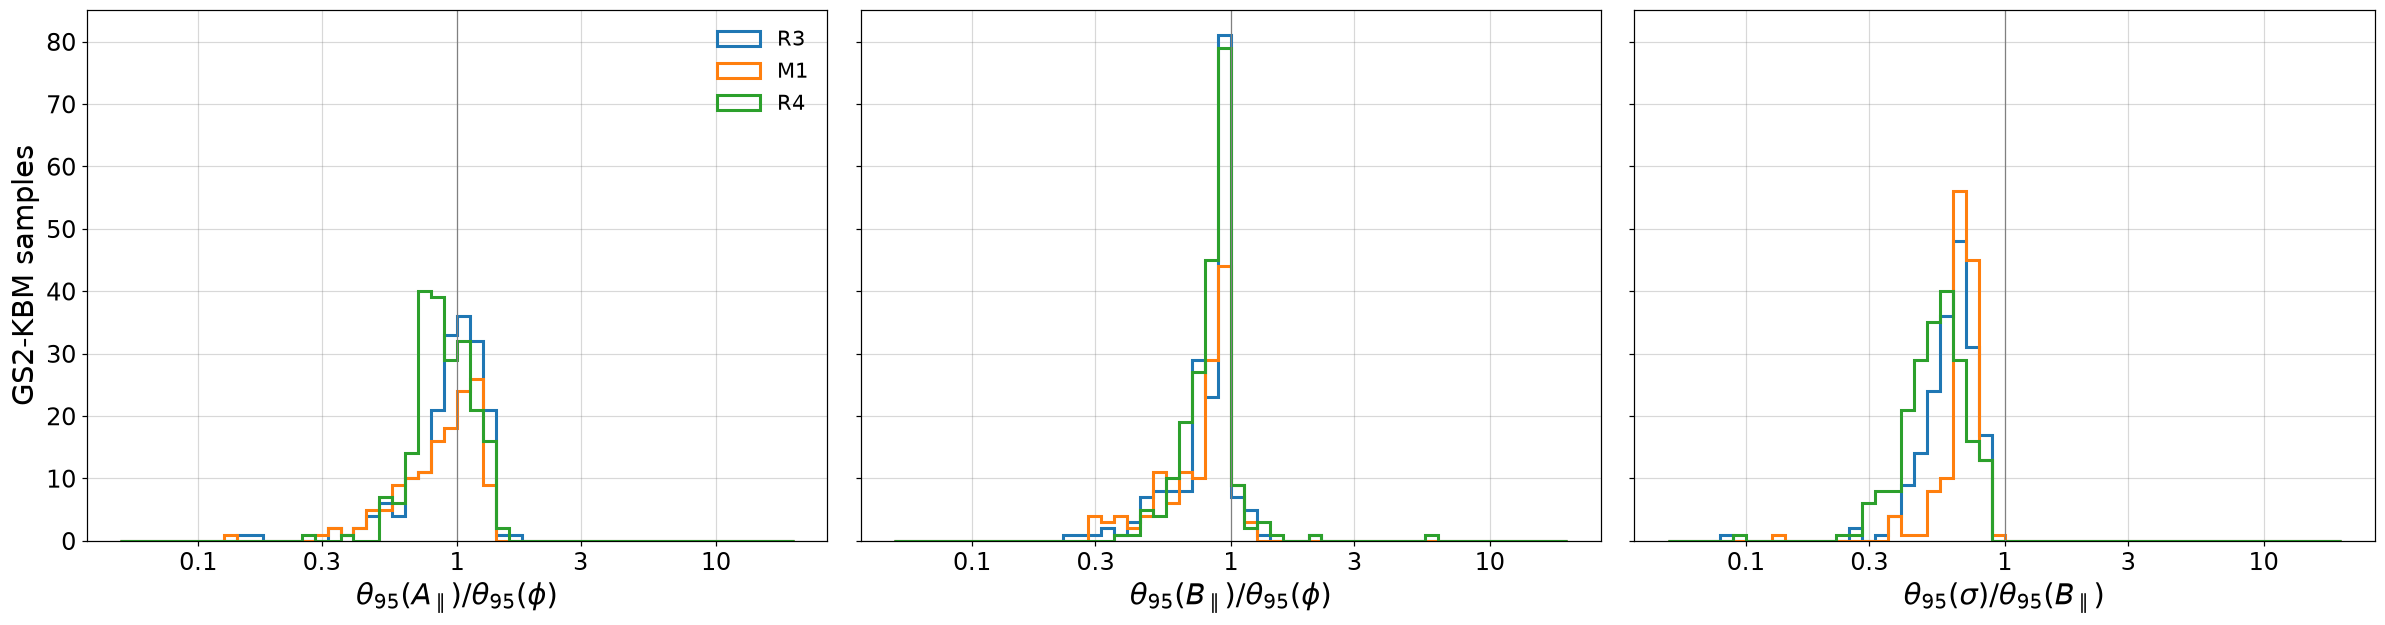

In [7]:
gs2["rho_A"] = gs2.theta95_apar / gs2.theta95_phi
gs2["rho_B"] = gs2.theta95_bpar / gs2.theta95_phi
gs2["sigma_over_B"] = gs2.theta95_sigma / gs2.theta95_bpar
gs2["sigma_over_phi"] = gs2.theta95_sigma / gs2.theta95_phi
ratios = {"rho_A": r"$\theta_{95}(A_\parallel)/\theta_{95}(\phi)$", "rho_B": r"$\theta_{95}(B_\parallel)/\theta_{95}(\phi)$",
          "sigma_over_B": r"$\theta_{95}(\sigma)/\theta_{95}(B_\parallel)$"}
rows = []
for ratio in [*ratios, "sigma_over_phi"]:
    values = gs2[ratio]
    rho = np.maximum(values, 1 / values)        # mismatch is symmetric: a narrower field costs the same as a wider one
    rows.append(dict(ratio=ratio, p10=values.quantile(0.1), median=values.median(), p90=values.quantile(0.9),
                     **{f"N_min_eps{eps:g}_median": np.median(n_epsilon(np.sqrt(rho), eps)) for eps in (0.1, 0.01)},
                     **{f"N_min_eps{eps:g}_p90": np.quantile(n_epsilon(np.sqrt(rho), eps), 0.9) for eps in (0.1, 0.01)}))
field_ratios = pd.DataFrame(rows)
print(field_ratios.round(2).to_string(index=False))
print("median theta95 [pi] by case:\n", (gs2.groupby("case")[["theta95_phi", "theta95_apar", "theta95_bpar", "theta95_sigma"]].median() / np.pi).round(3).to_string())

fig2, axes2 = plt.subplots(1, 3, figsize=(22, 6), sharey=True)
bins = np.logspace(-1.3, 1.3, 53)
for ax, (ratio, label) in zip(axes2, ratios.items()):
    for case, colour in zip(cases, ("C0", "C1", "C2")):
        ax.hist(gs2[gs2.case == case][ratio], bins=bins, histtype="step", lw=2, color=colour, label=case)
    ax.axvline(1, color="0.5", lw=0.8, marker="")
    ax.set(xscale="log", xlabel=label)
    log_xticks(ax, [0.1, 0.3, 1, 3, 10])
axes2[0].set_ylabel("GS2-KBM samples")
axes2[0].legend()
fig2.tight_layout()
fig2.savefig(plots_dir / "gs2_field_extent_ratio_histogram_per_database.png", dpi=150)
plt.show()